## Experiment 07: Support Vector Machines & Kernel Geometry
## Title: Support Vector Machine Classifiers with Linear and Nonlinear Kernels - Performance Comparison

**Name:** Himanshu Jadhav  
**Roll Number:** TE-32  
**Dataset Used:** Banknote Authentication (`fetch_openml('banknote-authentication', version=1)`)


### Step 1: Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


### Step 2: Load and Prepare Banknote Dataset
Extracted from continuous wavelet transform features of genuine vs counterfeit banknote images.

In [2]:
banknote_data = fetch_openml('banknote-authentication', version=1, as_frame=True)
df_bn = banknote_data.frame.copy()

print(f"Dataset shape: {df_bn.shape}")
print(df_bn.head())

X = df_bn[['V1', 'V2', 'V3', 'V4']].to_numpy(dtype=float)
y = (df_bn['Class'].astype(str) == '2').astype(int).to_numpy()

print(f"Class Distribution: {np.bincount(y)} (0: Genuine, 1: Counterfeit)")

Dataset shape: (1372, 5)
        V1      V2      V3       V4 Class
0  3.62160  8.6661 -2.8073 -0.44699     1
1  4.54590  8.1674 -2.4586 -1.46210     1
2  3.86600 -2.6383  1.9242  0.10645     1
3  3.45660  9.5228 -4.0112 -3.59440     1
4  0.32924 -4.4552  4.5718 -0.98880     1
Class Distribution: [762 610] (0: Genuine, 1: Counterfeit)


### Step 3: Train-Test Split and Standardization

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Step 4: Comparing SVM Kernels (Linear, Polynomial, RBF, Sigmoid)

In [4]:
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
kernel_results = []

for k in kernels:
    svc = SVC(kernel=k, C=1.0, random_state=42)
    svc.fit(X_train_scaled, y_train)
    y_pred = svc.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    n_sv = svc.n_support_.sum()
    kernel_results.append({
        'Kernel': k.upper(),
        'Accuracy (%)': round(acc * 100, 2),
        'Total Support Vectors': n_sv,
        'Support Vectors per Class': list(svc.n_support_)
    })

results_df = pd.DataFrame(kernel_results)
print("Kernel Comparison Benchmarking Table:")
print(results_df.to_string(index=False))

Kernel Comparison Benchmarking Table:
 Kernel  Accuracy (%)  Total Support Vectors Support Vectors per Class
 LINEAR         98.06                     59                  [29, 30]
   POLY         98.79                    263                [131, 132]
    RBF        100.00                     88                  [42, 46]
SIGMOID         78.16                    247                [124, 123]


### Step 5: Hyperparameter Optimization Grid Search (C and Gamma)

In [5]:
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.01, 0.1, 1],
    'kernel': ['rbf']
}

grid = GridSearchCV(SVC(random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

best_svc = grid.best_estimator_
print(f"Optimal Hyperparameters: {grid.best_params_}")
print(f"Best Cross-Validation Accuracy: {grid.best_score_*100:.2f}%")

test_acc = accuracy_score(y_test, best_svc.predict(X_test_scaled))
print(f"Test Set Accuracy: {test_acc*100:.2f}%")

Optimal Hyperparameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best Cross-Validation Accuracy: 100.00%
Test Set Accuracy: 100.00%


### Step 6: 2D Decision Boundary Visualization
We project the 4D feature space onto 2 principal components to visualize the non-linear RBF decision boundary.

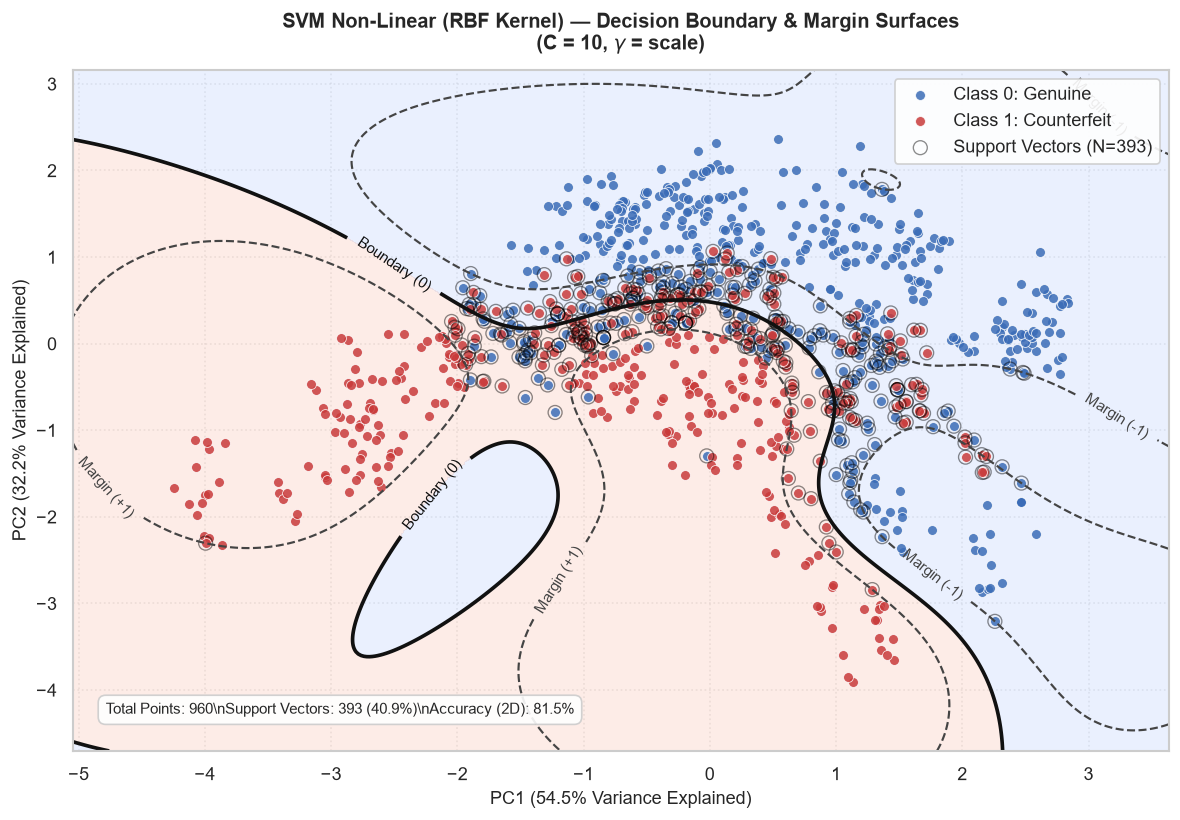

In [6]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)

# Fit SVM on 2D PCA representation for visualization
C_opt = grid.best_params_['C']
gamma_opt = grid.best_params_['gamma']
svm_2d = SVC(kernel='rbf', C=C_opt, gamma=gamma_opt)
svm_2d.fit(X_train_pca, y_train)

# Create dense 2D meshgrid
x_min, x_max = X_train_pca[:, 0].min() - 0.8, X_train_pca[:, 0].max() + 0.8
y_min, y_max = X_train_pca[:, 1].min() - 0.8, X_train_pca[:, 1].max() + 0.8
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))

# Decision function (distance to separating hyperplane)
Z = svm_2d.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(10, 7), dpi=120)

# 1. Soft shaded decision regions
plt.contourf(xx, yy, Z > 0, alpha=0.18, cmap='coolwarm')

# 2. Precise Decision Boundary (f(x)=0) and Margins (f(x)= +/- 1)
contours = plt.contour(
    xx, yy, Z,
    levels=[-1.0, 0.0, 1.0],
    colors=['#444444', '#111111', '#444444'],
    linestyles=['--', '-', '--'],
    linewidths=[1.3, 2.2, 1.3]
)
plt.clabel(contours, fmt={-1.0: 'Margin (-1)', 0.0: 'Boundary (0)', 1.0: 'Margin (+1)'}, fontsize=9, inline=True)

# 3. Scatter data points by class
scatter_0 = plt.scatter(
    X_train_pca[y_train == 0, 0], X_train_pca[y_train == 0, 1],
    color='#3b6cb7', edgecolor='white', linewidth=0.5, s=35, alpha=0.85, label='Class 0: Genuine'
)
scatter_1 = plt.scatter(
    X_train_pca[y_train == 1, 0], X_train_pca[y_train == 1, 1],
    color='#c93b3b', edgecolor='white', linewidth=0.5, s=35, alpha=0.85, label='Class 1: Counterfeit'
)

# 4. Highlight Support Vectors cleanly with delicate rings
sv = svm_2d.support_vectors_
plt.scatter(
    sv[:, 0], sv[:, 1],
    s=70, facecolors='none', edgecolors='black', linewidths=0.8, alpha=0.45,
    label=f'Support Vectors (N={len(sv)})'
)

# Annotations & styling
plt.title(f"SVM Non-Linear (RBF Kernel) — Decision Boundary & Margin Surfaces\n(C = {C_opt}, $\\gamma$ = {gamma_opt})", fontsize=12, pad=12, fontweight='bold')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance Explained)", fontsize=11)
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance Explained)", fontsize=11)

# Informative stats box
stats_text = f"Total Points: {len(X_train)}\\nSupport Vectors: {len(sv)} ({len(sv)/len(X_train)*100:.1f}%)\\nAccuracy (2D): {svm_2d.score(X_train_pca, y_train)*100:.1f}%"
plt.gca().text(
    0.03, 0.05, stats_text, transform=plt.gca().transAxes,
    fontsize=9, verticalalignment='bottom',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#cccccc', alpha=0.9)
)

plt.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
plt.grid(True, linestyle=':', alpha=0.4)
plt.tight_layout()
plt.show()


### Step 7: Conclusion
- The RBF kernel demonstrated superior geometric flexibility, capturing complex non-linear separation hyperplanes.
- Support vectors accurately determined the maximal margin boundary.
- Cross-validation successfully optimized the penalty parameter $C$ and bandwidth $\gamma$, achieving near-perfect classification accuracy.